In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv(r"C:\Users\leisi\OneDrive\Documents\GROUP_07_Beijing_Air_Quality_Cleaned.csv")

df["datetime"] = pd.to_datetime(df["datetime"])

df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (420768, 19)

Column Names:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station', 'datetime']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 19 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   No        420768 non-null  int64         
 1   year      420768 non-null  int64         
 2   month     420768 non-null  int64         
 3   day       420768 non-null  int64         
 4   hour      420768 non-null  int64         
 5   PM2.5     420768 non-null  float64       
 6   PM10      420768 non-null  float64       
 7   SO2       420768 non-null  float64       
 8   NO2       420768 non-null  float64       
 9   CO        420768 non-null  float64       
 10  O3        420768 non-null  float64       
 11  TEMP      420768 non-null  float64       
 12  PRES      420768 non-

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nNumber of Stations:")
print(df["station"].nunique())

Missing Values:
No          0
year        0
month       0
day         0
hour        0
PM2.5       0
PM10        0
SO2         0
NO2         0
CO          0
O3          0
TEMP        0
PRES        0
DEWP        0
RAIN        0
wd          0
WSPM        0
station     0
datetime    0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0

Number of Stations:
12


In [5]:
df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,datetime
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.839718,104.910268,15.913090,50.599018,1235.682649,57.237872,13.531692,1010.753337,2.482421,0.064428,1.730034,2015-03-01 11:30:00
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000,2013-03-01 00:00:00
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,10.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000,2014-03-01 05:45:00
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,44.000000,14.500000,1010.400000,3.000000,0.000000,1.400000,2015-03-01 11:30:00
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000,2016-02-29 17:15:00
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000,2017-02-28 23:00:00
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.950217,92.431422,21.896609,35.171921,1161.790893,57.135195,11.437867,10.474302,13.797675,0.820638,1.246674,NaN


In [6]:
print("PM2.5 Descriptive Statistics:")
print(df["PM2.5"].describe())

print("\nMedian PM2.5:", df["PM2.5"].median())
print("Most Frequent PM2.5:", df["PM2.5"].mode()[0])
print("Skewness:", df["PM2.5"].skew())
print("Kurtosis:", df["PM2.5"].kurt())

PM2.5 Descriptive Statistics:
count    420768.000000
mean         79.839718
std          80.950217
min           2.000000
25%          20.000000
50%          55.000000
75%         111.000000
max         999.000000
Name: PM2.5, dtype: float64

Median PM2.5: 55.0
Most Frequent PM2.5: 3.0
Skewness: 2.0202932554127018
Kurtosis: 5.975231696248311


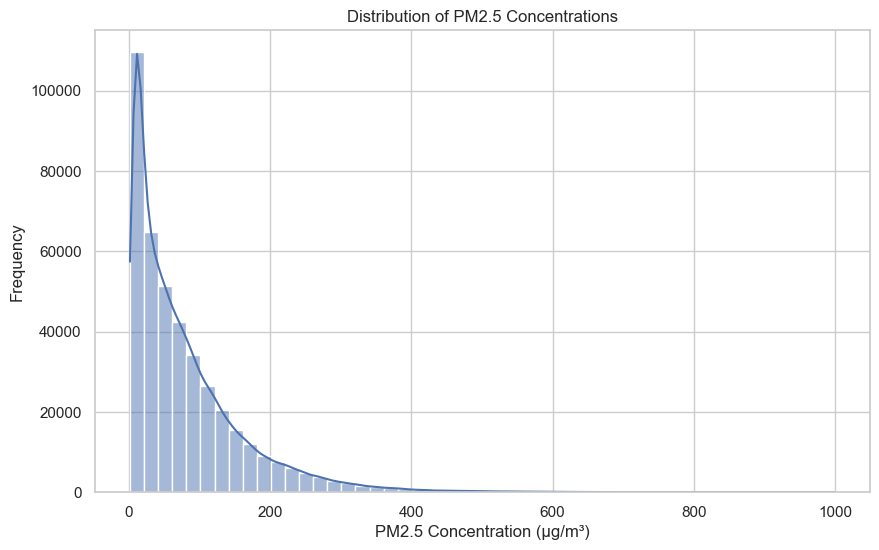

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="PM2.5",
    bins=50,
    kde=True
)

plt.title("Distribution of PM2.5 Concentrations")
plt.xlabel("PM2.5 Concentration (µg/m³)")
plt.ylabel("Frequency")

plt.show()

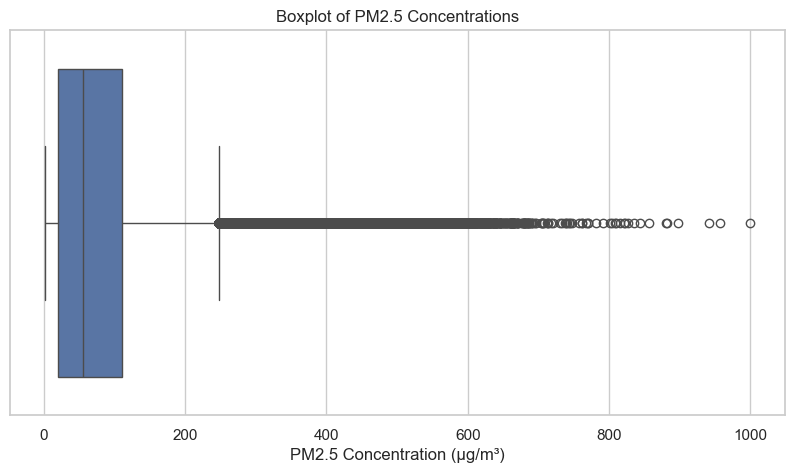

In [8]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["PM2.5"])

plt.title("Boxplot of PM2.5 Concentrations")
plt.xlabel("PM2.5 Concentration (µg/m³)")

plt.show()

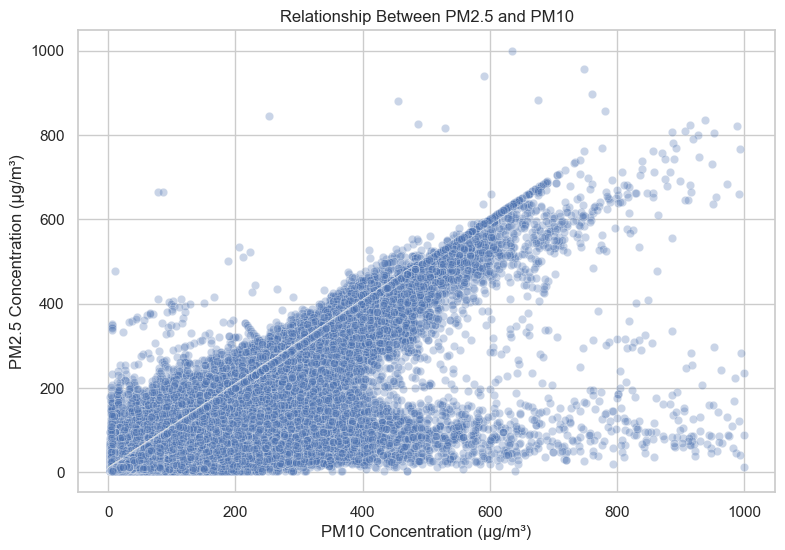

In [9]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="PM10",
    y="PM2.5",
    alpha=0.3
)

plt.title("Relationship Between PM2.5 and PM10")
plt.xlabel("PM10 Concentration (µg/m³)")
plt.ylabel("PM2.5 Concentration (µg/m³)")

plt.show()

In [10]:
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["hour"] = df["datetime"].dt.hour

df[["datetime", "year", "month", "hour", "PM2.5"]].head()

,datetime,year,month,hour,PM2.5
0,2013-03-01 00:00:00,2013,3,0,4.0
1,2013-03-01 01:00:00,2013,3,1,8.0
2,2013-03-01 02:00:00,2013,3,2,7.0
3,2013-03-01 03:00:00,2013,3,3,6.0
4,2013-03-01 04:00:00,2013,3,4,3.0


In [11]:
yearly_pm25 = df.groupby("year")["PM2.5"].mean()

print(yearly_pm25)

year
2013    79.768553
2014    86.183671
2015    79.306423
2016    72.078419
2017    92.407898
Name: PM2.5, dtype: float64


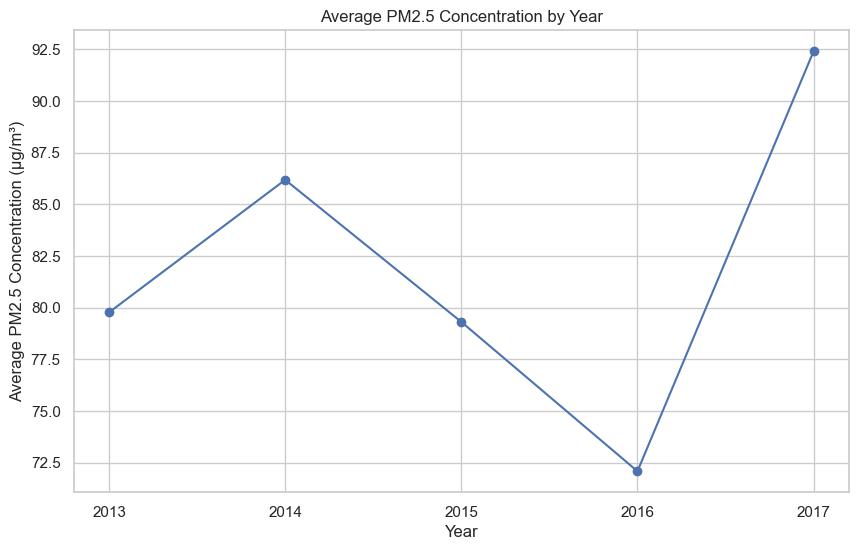

In [12]:
plt.figure(figsize=(10, 6))

yearly_pm25.plot(kind="line", marker="o")

plt.title("Average PM2.5 Concentration by Year")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.xticks(yearly_pm25.index)

plt.show()

In [13]:
monthly_pm25 = df.groupby("month")["PM2.5"].mean()

print(monthly_pm25)

month
1      93.760559
2      89.213391
3      94.594295
4      73.367153
5      63.541148
6      68.837547
7      71.401115
8      53.465479
9      61.281071
10     91.715859
11     93.323963
12    103.679184
Name: PM2.5, dtype: float64


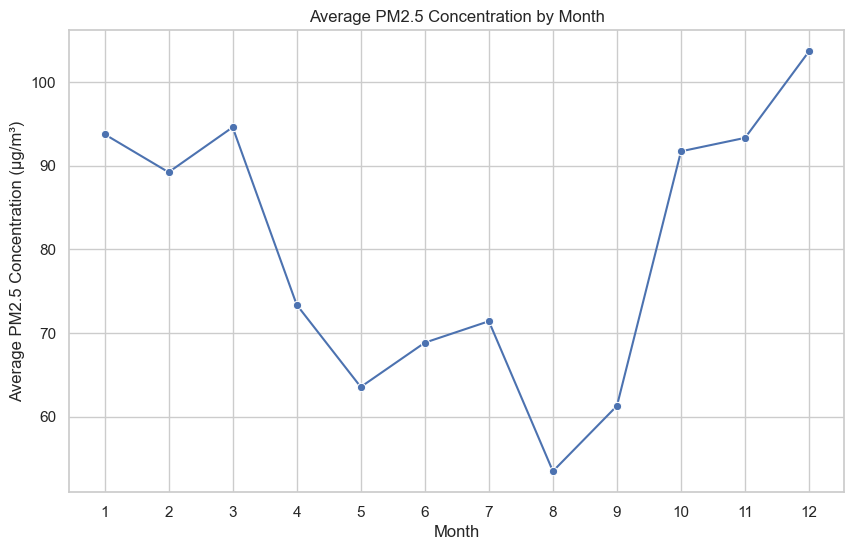

In [14]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    x=monthly_pm25.index,
    y=monthly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 Concentration by Month")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.xticks(range(1, 13))

plt.show()

In [15]:
hourly_pm25 = df.groupby("hour")["PM2.5"].mean()

print(hourly_pm25)

hour
0     87.696481
1     86.848406
2     84.803844
3     82.212727
4     79.465989
5     76.538028
6     74.289174
7     73.424078
8     74.403840
9     76.061597
10    77.126229
11    77.142663
12    76.548181
13    76.048575
14    75.462557
15    74.560780
16    74.399300
17    75.524938
18    78.014513
19    82.503641
20    86.636117
21    88.813470
22    89.032249
23    88.595867
Name: PM2.5, dtype: float64


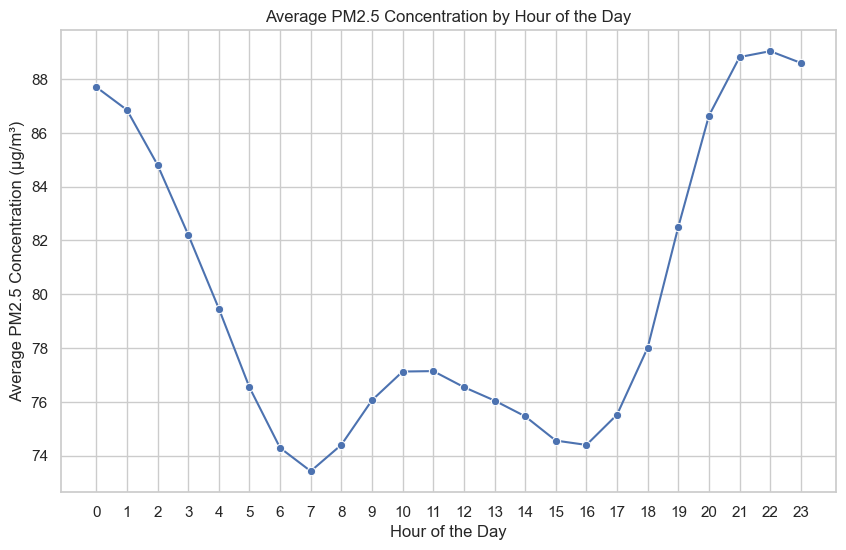

In [16]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    x=hourly_pm25.index,
    y=hourly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 Concentration by Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.xticks(range(0, 24))

plt.show()

In [17]:
station_pm25 = (
    df.groupby("station")["PM2.5"]
    .mean()
    .sort_values(ascending=False)
)

print(station_pm25)

station
Dongsi           86.144243
Nongzhanguan     85.079472
Wanshouxigong    85.067548
Gucheng          84.074802
Wanliu           83.467612
Guanyuan         82.897522
Aotizhongxin     82.540623
Tiantan          82.033097
Shunyi           79.437962
Changping        70.986438
Huairou          69.501747
Dingling         66.845557
Name: PM2.5, dtype: float64


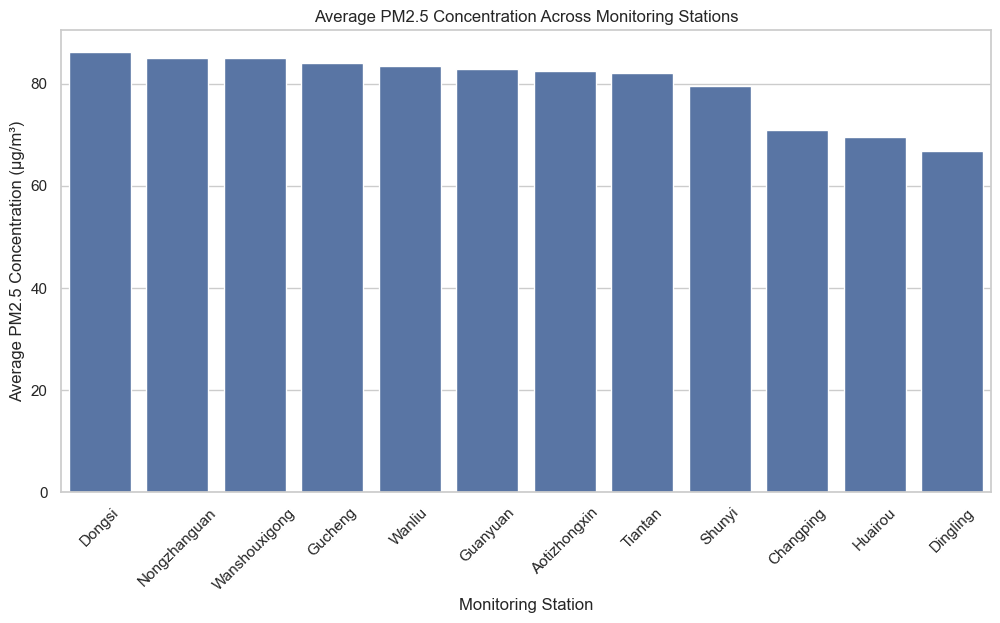

In [18]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=station_pm25.index,
    y=station_pm25.values
)

plt.title("Average PM2.5 Concentration Across Monitoring Stations")
plt.xlabel("Monitoring Station")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.xticks(rotation=45)

plt.show()

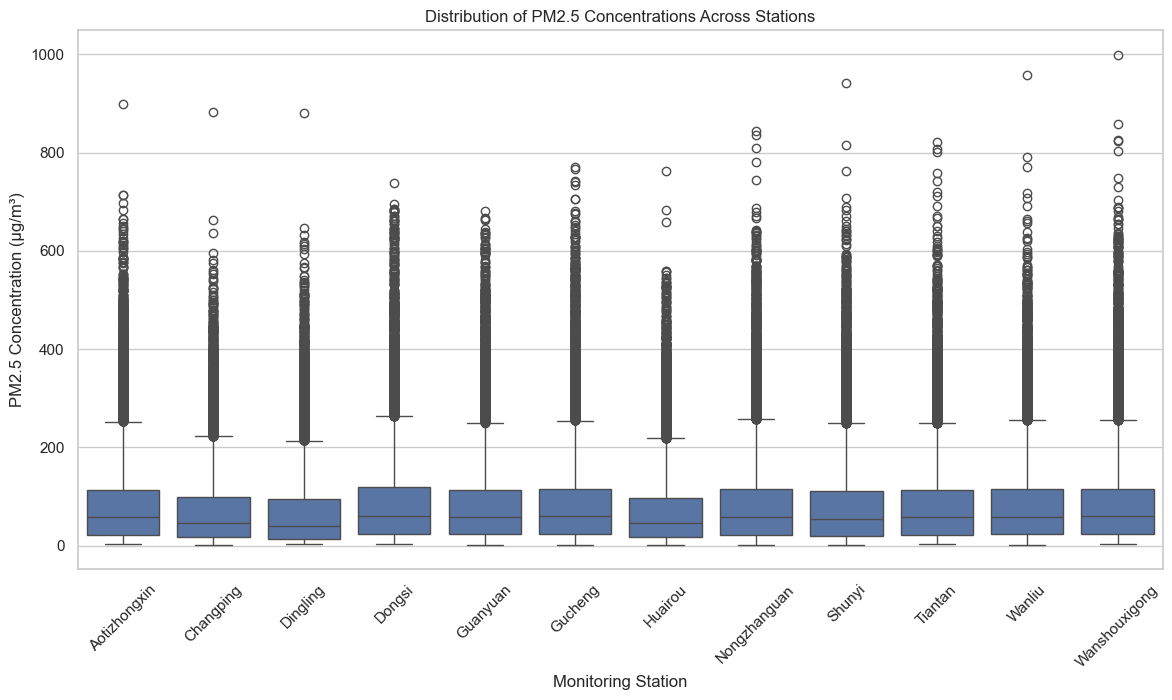

In [19]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="station",
    y="PM2.5"
)

plt.title("Distribution of PM2.5 Concentrations Across Stations")
plt.xlabel("Monitoring Station")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.xticks(rotation=45)

plt.show()

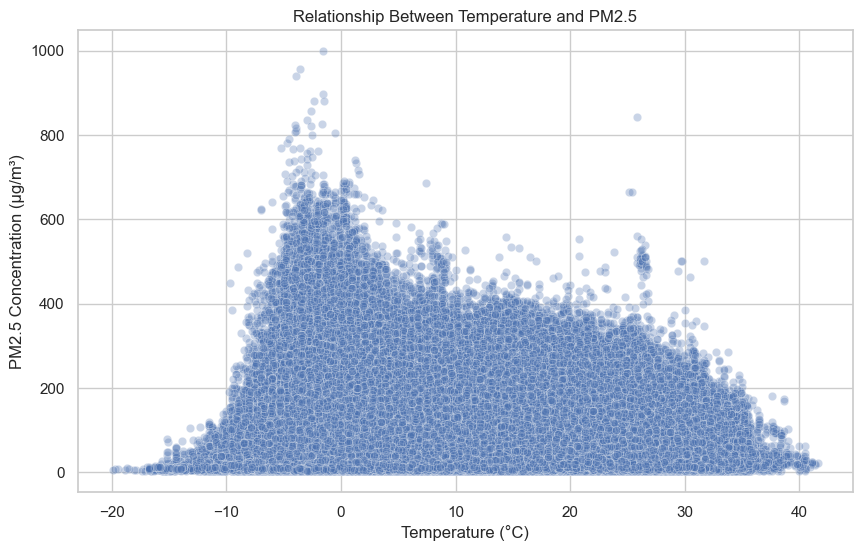

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="TEMP",
    y="PM2.5",
    alpha=0.3
)

plt.title("Relationship Between Temperature and PM2.5")
plt.xlabel("Temperature (°C)")
plt.ylabel("PM2.5 Concentration (µg/m³)")

plt.show()

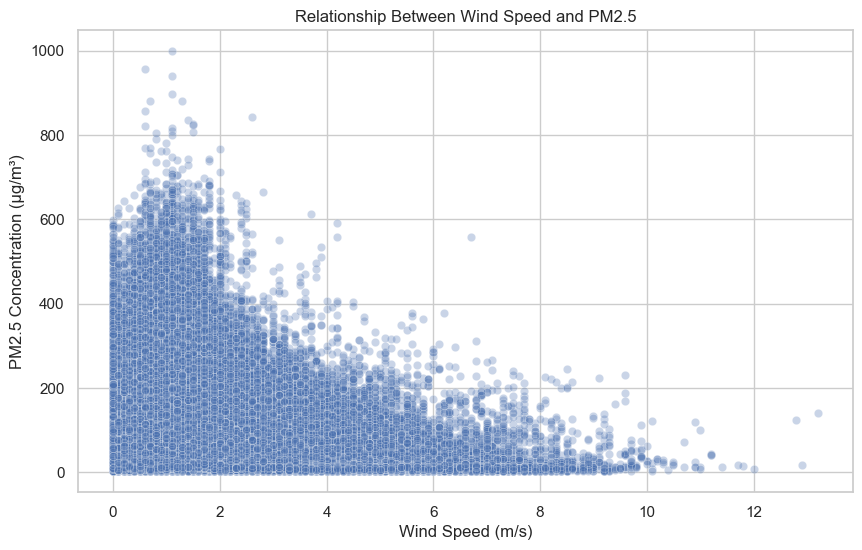

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="WSPM",
    y="PM2.5",
    alpha=0.3
)

plt.title("Relationship Between Wind Speed and PM2.5")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("PM2.5 Concentration (µg/m³)")

plt.show()

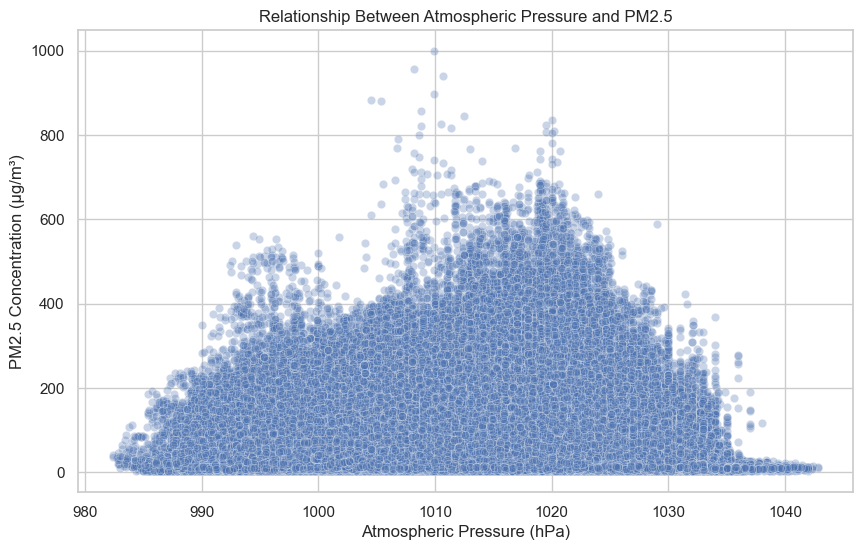

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="PRES",
    y="PM2.5",
    alpha=0.3
)

plt.title("Relationship Between Atmospheric Pressure and PM2.5")
plt.xlabel("Atmospheric Pressure (hPa)")
plt.ylabel("PM2.5 Concentration (µg/m³)")

plt.show()

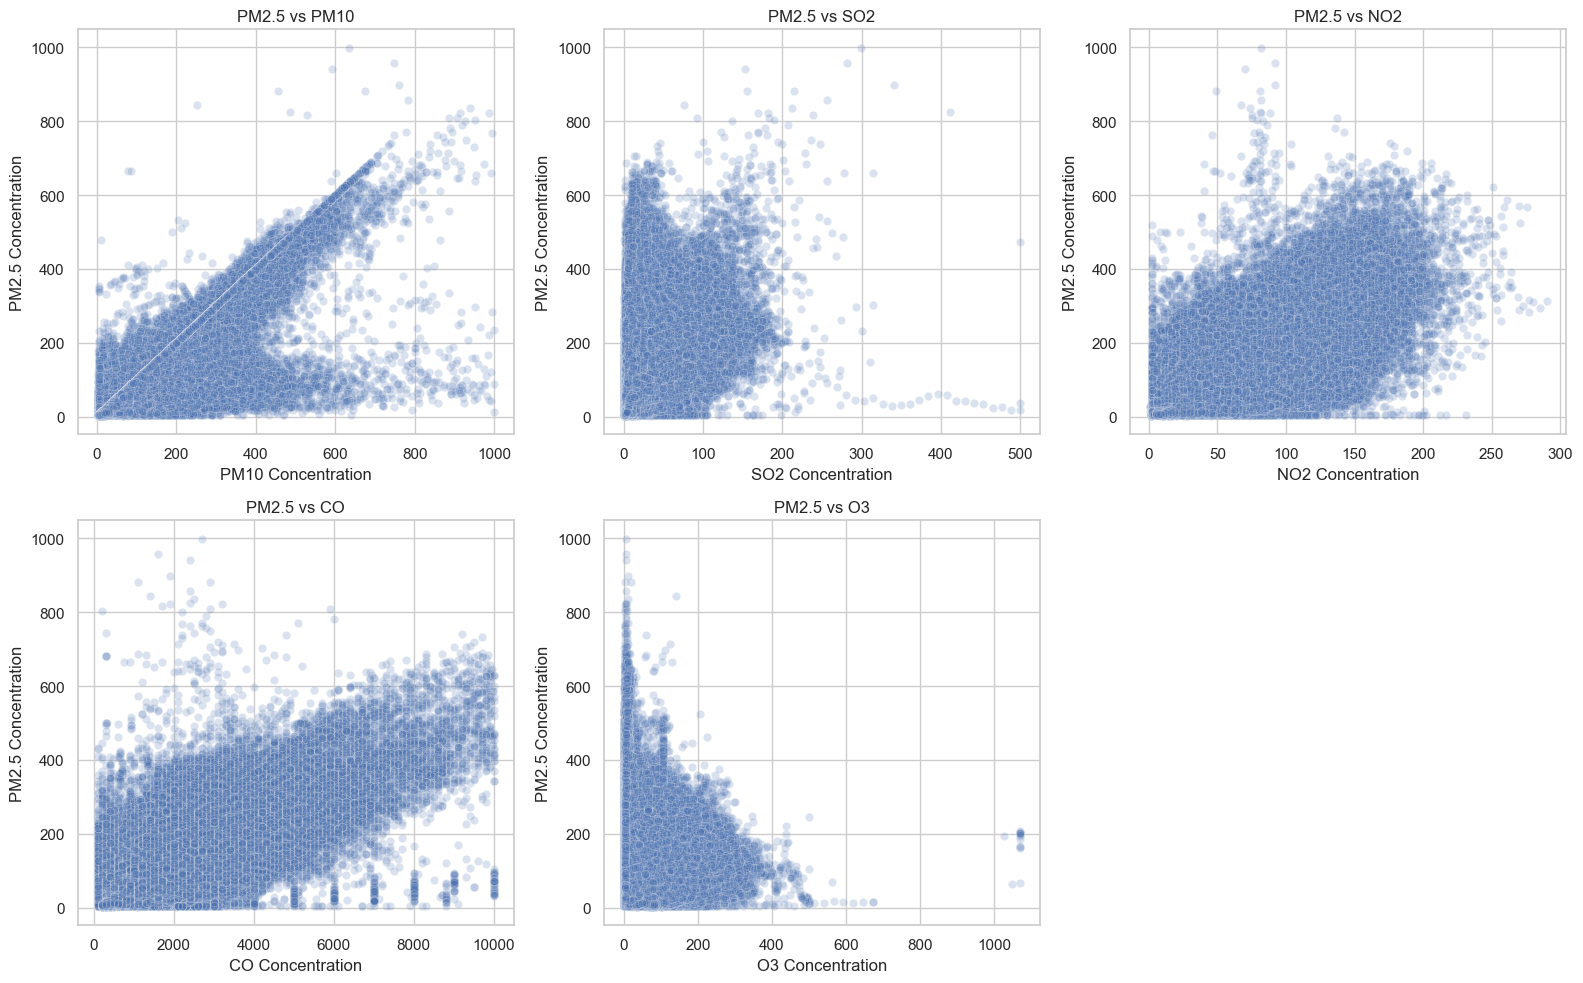

In [23]:
pollutants = ["PM10", "SO2", "NO2", "CO", "O3"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, pollutant in zip(axes.flatten(), pollutants):
    sns.scatterplot(
        data=df,
        x=pollutant,
        y="PM2.5",
        alpha=0.2,
        ax=ax
    )

    ax.set_title(f"PM2.5 vs {pollutant}")
    ax.set_xlabel(f"{pollutant} Concentration")
    ax.set_ylabel("PM2.5 Concentration")

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [24]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

correlation_matrix

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
No,1.000000,9.695331e-01,4.318051e-02,1.776442e-02,6.838683e-04,-0.024719,-0.047232,-0.227029,-0.047030,0.019026,-0.040679,-0.122671,0.188618,-0.102117,0.004812,0.054354
year,0.969533,1.000000e+00,-2.020099e-01,-5.569082e-03,-2.115260e-15,-0.026070,-0.039717,-0.170455,-0.055442,0.007489,-0.013782,-0.152312,0.187214,-0.165189,0.000894,0.087666
month,0.043181,-2.020099e-01,1.000000e+00,1.052232e-02,-1.905981e-16,0.006540,-0.029467,-0.214820,0.036375,0.046000,-0.105752,0.132502,-0.013835,0.266779,0.016136,-0.139920
day,0.017764,-5.569082e-03,1.052232e-02,1.000000e+00,1.013388e-17,0.005445,0.027416,-0.001980,0.012441,-0.015630,-0.000510,0.014219,0.021971,0.022988,-0.003716,-0.011426
hour,0.000684,-2.115260e-15,-1.905981e-16,1.013388e-17,1.000000e+00,0.011129,0.049566,0.028943,-0.001756,-0.031367,0.277433,0.142173,-0.038464,-0.011966,0.012371,0.140396
PM2.5,-0.024719,-2.606991e-02,6.539506e-03,5.445498e-03,1.112889e-02,1.000000,0.878874,0.478223,0.664317,0.780165,-0.149508,-0.131607,0.019862,0.113045,-0.014452,-0.271425
PM10,-0.047232,-3.971735e-02,-2.946699e-02,2.741647e-02,4.956631e-02,0.878874,1.000000,0.460572,0.645598,0.691887,-0.110443,-0.096078,-0.018375,0.067674,-0.026505,-0.178200
SO2,-0.227029,-1.704546e-01,-2.148197e-01,-1.980077e-03,2.894252e-02,0.478223,0.460572,1.000000,0.495827,0.522678,-0.165311,-0.320237,0.221235,-0.266121,-0.040028,-0.108536
NO2,-0.047030,-5.544211e-02,3.637488e-02,1.244060e-02,-1.756062e-03,0.664317,0.645598,0.495827,1.000000,0.694030,-0.465913,-0.277231,0.176605,-0.032512,-0.043661,-0.395716
CO,0.019026,7.488632e-03,4.599987e-02,-1.562982e-02,-3.136714e-02,0.780165,0.691887,0.522678,0.694030,1.000000,-0.306979,-0.324057,0.188045,-0.060315,-0.013281,-0.290413


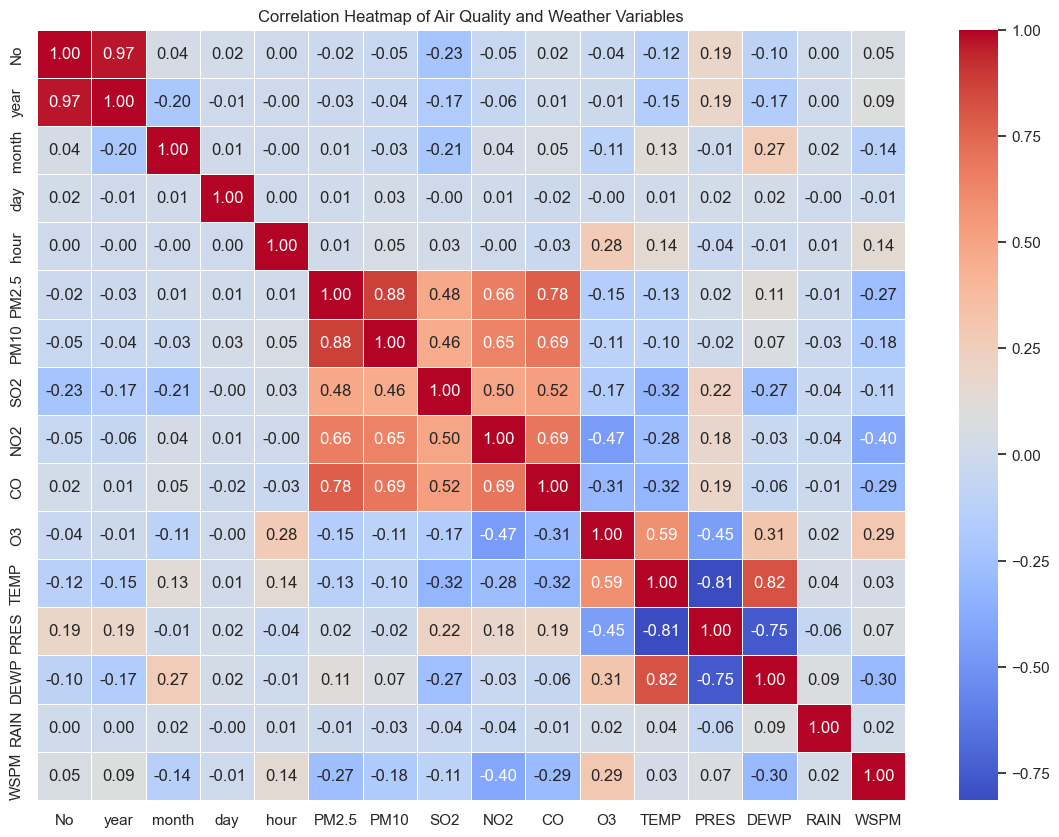

In [25]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Air Quality and Weather Variables")

plt.show()

In [26]:
pm25_correlations = (
    correlation_matrix["PM2.5"]
    .drop("PM2.5")
    .sort_values(ascending=False)
)

print("Correlation of Other Variables with PM2.5:")
print(pm25_correlations)

Correlation of Other Variables with PM2.5:
PM10     0.878874
CO       0.780165
NO2      0.664317
SO2      0.478223
DEWP     0.113045
PRES     0.019862
hour     0.011129
month    0.006540
day      0.005445
RAIN    -0.014452
No      -0.024719
year    -0.026070
TEMP    -0.131607
O3      -0.149508
WSPM    -0.271425
Name: PM2.5, dtype: float64


In [27]:
station_summary = df.groupby("station")["PM2.5"].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)

station_summary

,mean,median,std,min,max
station,,,,,
Aotizhongxin,82.54,58.0,81.96,3.0,898.0
Changping,70.99,46.0,72.40,2.0,882.0
Dingling,66.85,41.0,73.45,3.0,881.0
Dongsi,86.14,61.0,86.26,3.0,737.0
Guanyuan,82.90,59.0,81.07,2.0,680.0
Gucheng,84.07,60.0,82.99,2.0,770.0
Huairou,69.50,47.0,70.99,2.0,762.0
Nongzhanguan,85.08,59.0,86.69,2.0,844.0
Shunyi,79.44,55.0,81.50,2.0,941.0


In [28]:
year_summary = df.groupby("year")["PM2.5"].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)

year_summary

,mean,median,std,min,max
year,,,,,
2013,79.77,59.0,72.56,2.0,844.0
2014,86.18,63.0,82.81,3.0,809.0
2015,79.31,52.0,84.01,3.0,762.0
2016,72.08,49.0,75.64,3.0,999.0
2017,92.41,47.0,112.29,2.0,835.0


In [29]:
highest_station = station_pm25.idxmax()
lowest_station = station_pm25.idxmin()

print("Station with Highest Average PM2.5:")
print(highest_station, ":", round(station_pm25.max(), 2), "µg/m³")

print("\nStation with Lowest Average PM2.5:")
print(lowest_station, ":", round(station_pm25.min(), 2), "µg/m³")

Station with Highest Average PM2.5:
Dongsi : 86.14 µg/m³

Station with Lowest Average PM2.5:
Dingling : 66.85 µg/m³


In [30]:
most_polluted_month = monthly_pm25.idxmax()
least_polluted_month = monthly_pm25.idxmin()

most_polluted_hour = hourly_pm25.idxmax()
least_polluted_hour = hourly_pm25.idxmin()

print("Month with Highest Average PM2.5:", most_polluted_month)
print("Month with Lowest Average PM2.5:", least_polluted_month)

print("\nHour with Highest Average PM2.5:", most_polluted_hour)
print("Hour with Lowest Average PM2.5:", least_polluted_hour)

Month with Highest Average PM2.5: 12
Month with Lowest Average PM2.5: 8

Hour with Highest Average PM2.5: 22
Hour with Lowest Average PM2.5: 7


In [31]:
print("Strongest Positive Correlations with PM2.5:")
print(pm25_correlations.head(5))

print("\nStrongest Negative Correlations with PM2.5:")
print(pm25_correlations.tail(5))

Strongest Positive Correlations with PM2.5:
PM10    0.878874
CO      0.780165
NO2     0.664317
SO2     0.478223
DEWP    0.113045
Name: PM2.5, dtype: float64

Strongest Negative Correlations with PM2.5:
No     -0.024719
year   -0.026070
TEMP   -0.131607
O3     -0.149508
WSPM   -0.271425
Name: PM2.5, dtype: float64


In [32]:
print("========== AIR QUALITY EDA SUMMARY ==========")

print("\nDataset Information")
print("Total observations:", len(df))
print("Number of stations:", df["station"].nunique())
print("Number of variables:", df.shape[1])

print("\nPM2.5 Statistics")
print("Mean:", round(df["PM2.5"].mean(), 2))
print("Median:", round(df["PM2.5"].median(), 2))
print("Standard deviation:", round(df["PM2.5"].std(), 2))
print("Minimum:", df["PM2.5"].min())
print("Maximum:", df["PM2.5"].max())

print("\nStation Analysis")
print("Highest pollution station:", highest_station)
print("Lowest pollution station:", lowest_station)

print("\nTemporal Analysis")
print("Most polluted month:", most_polluted_month)
print("Least polluted month:", least_polluted_month)
print("Most polluted hour:", most_polluted_hour)
print("Least polluted hour:", least_polluted_hour)

print("\nEDA analysis completed.")

========== AIR QUALITY EDA SUMMARY ==========

Dataset Information
Total observations: 420768
Number of stations: 12
Number of variables: 19

PM2.5 Statistics
Mean: 79.84
Median: 55.0
Standard deviation: 80.95
Minimum: 2.0
Maximum: 999.0

Station Analysis
Highest pollution station: Dongsi
Lowest pollution station: Dingling

Temporal Analysis
Most polluted month: 12
Least polluted month: 8
Most polluted hour: 22
Least polluted hour: 7

EDA analysis completed.


In [33]:
station_summary.to_csv("GROUP_07_Station_PM25_Summary.csv")

In [34]:
year_summary.to_csv("GROUP_07_Yearly_PM25_Summary.csv")

In [35]:
pm25_correlations.to_csv("GROUP_07_PM25_Correlations.csv")

In [36]:
df.to_csv("GROUP_07_EDA_Analysis_Dataset.csv", index=False)

### Interpretation of PM2.5 Distribution

The histogram illustrates the distribution of PM2.5 concentrations
across the observations in the dataset. The shape of the distribution
helps identify whether pollution levels are concentrated around
particular values or whether the data contains extreme observations.

The distribution is important because it helps us understand the
behaviour of the target variable before developing prediction models.